# Assignment 2

## Extract data from the json file

Write a script, that would extract all the the data from the json file and return it in a list of texts for further use in the next tasks

In [1]:
import json
import os

def extract_texts_from_file(file_path):
    """
    Extract the text data from the json file

    Args:
        file_path (str): Relative location of the json file in the project.

    Returns:
        list: The list of texts as strings.
    """
    if not os.path.exists(file_path):
        fallback_path = os.path.join("resources", "weather.json")
        if os.path.exists(fallback_path):
            file_path = fallback_path
        elif os.path.exists("weather.json"):
            file_path = "weather.json"
        else:
            raise FileNotFoundError(f"JSON file not found at: {file_path}")

    with open(file_path, "r", encoding="utf-8") as f:
        data = json.load(f)

    texts = []

    if isinstance(data, dict) and "daily" in data:
        city = data.get("city", "Unknown City")
        timezone = data.get("timezone", "UTC")
        for item in data.get("daily", []):
            desc = item.get("weather_description", "Normal weather")
            date = item.get("date", "")
            max_t = item.get("max_temperature", 0.0)
            min_t = item.get("min_temperature", 0.0)
            precip = item.get("precipitation", 0.0)
            wind = item.get("wind_speed", 0.0)
            hum = item.get("humidity", 0)

            temp_word = "hot tropical" if max_t >= 32 else "warm mild"
            rain_word = "wet rainy showers" if precip > 0 else "dry sunny clear"
            wind_word = "strong breezy gusts" if wind >= 15 else "calm light breeze"
            hum_word = "high humid moisture" if hum >= 70 else "moderate comfortable air"

            text = (
                f"{desc} in {city} ({timezone}) on {date}: {temp_word} max temp {max_t}C "
                f"and min temp {min_t}C, {rain_word} with precip {precip}mm, "
                f"{wind_word} at wind spd {wind}km/h, {hum_word} with hum {hum}%."
            )
            texts.append(text)
    elif isinstance(data, list):
        for item in data:
            if isinstance(item, str):
                texts.append(item)
            elif isinstance(item, dict):
                texts.append(" ".join(str(v) for v in item.values() if v is not None))
            else:
                texts.append(str(item))
    elif isinstance(data, dict):
        for key, value in data.items():
            if isinstance(value, str):
                texts.append(f"{key}: {value}")
            elif isinstance(value, list):
                texts.extend(str(v) for v in value)

    return texts

texts = extract_texts_from_file('resources/weather.json')
for i, doc in enumerate(texts, 1):
    print(f"[{i}] {doc}")

[1] Clear sky in Tokyo (Asia/Tokyo) on 2024-08-18: hot tropical max temp 32.5C and min temp 22.5C, dry sunny clear with precip 0.0mm, strong breezy gusts at wind spd 15.5km/h, moderate comfortable air with hum 65%.
[2] Light rain in Tokyo (Asia/Tokyo) on 2024-08-19: warm mild max temp 30.0C and min temp 21.0C, wet rainy showers with precip 5.0mm, calm light breeze at wind spd 10.0km/h, high humid moisture with hum 70%.
[3] Moderate rain in Tokyo (Asia/Tokyo) on 2024-08-20: warm mild max temp 28.0C and min temp 20.0C, wet rainy showers with precip 10.0mm, calm light breeze at wind spd 8.0km/h, high humid moisture with hum 80%.
[4] Sunny in Tokyo (Asia/Tokyo) on 2024-08-21: hot tropical max temp 33.0C and min temp 24.0C, dry sunny clear with precip 0.0mm, strong breezy gusts at wind spd 20.0km/h, moderate comfortable air with hum 60%.


## Process the texts

Write a script, that would process these texts. Processing should include:

- Lowercasing
- Removing Punctuation
- Removing Special Characters and Numbers
- Stemming or Lemmatization
- Handling Abbreviations
- Spelling Correction

In [2]:
import re
import string
from difflib import get_close_matches

ABBREVIATIONS = {
    "can't": "cannot",
    "won't": "will not",
    "don't": "do not",
    "doesn't": "does not",
    "didn't": "did not",
    "isn't": "is not",
    "aren't": "are not",
    "wasn't": "was not",
    "weren't": "were not",
    "it's": "it is",
    "km/h": "kilometers per hour",
    "kmh": "kilometers per hour",
    "mph": "miles per hour",
    "max": "maximum",
    "min": "minimum",
    "temp": "temperature",
    "temps": "temperatures",
    "precip": "precipitation",
    "hum": "humidity",
    "spd": "speed",
    "vis": "visibility",
    "dir": "direction",
    "deg": "degrees",
    "hpa": "hectopascals",
    "avg": "average",
    "approx": "approximately",
    "info": "information",
    "etc": "et cetera"
}

SPELLING_CORRECTIONS = {
    "wether": "weather",
    "weahter": "weather",
    "temprature": "temperature",
    "tempereture": "temperature",
    "preciptation": "precipitation",
    "humdity": "humidity",
    "forcast": "forecast",
    "lightening": "lightning",
    "thundrstorm": "thunderstorm",
    "modrate": "moderate",
    "comfrtable": "comfortable"
}

KNOWN_VOCABULARY = {
    "clear", "sky", "light", "rain", "moderate", "sunny", "day", "weather",
    "forecast", "tokyo", "asia", "hot", "tropical", "warm", "mild", "maximum",
    "minimum", "temperature", "celsius", "wet", "rainy", "shower", "showers",
    "dry", "precipitation", "millimeter", "millimeters", "strong", "breezy",
    "gust", "gusts", "calm", "breeze", "wind", "speed", "kilometer",
    "kilometers", "per", "hour", "high", "humid", "moisture", "comfortable",
    "air", "humidity", "snow", "fog", "thunderstorm", "cloud", "cloudy",
    "overcast", "freezing", "cold", "cool", "visibility", "pressure", "storm",
    "winter", "summer", "spring", "autumn", "heavy", "dense", "mist", "freezing"
}

STOP_WORDS = {
    "in", "on", "at", "with", "and", "the", "a", "an", "of", "to", "for", "is", "are", "was", "were", "per"
}

IRREGULAR_LEMMAS = {
    "skies": "sky",
    "showers": "shower",
    "gusts": "gust",
    "kilometers": "kilometer",
    "millimeters": "millimeter",
    "temperatures": "temperature",
    "degrees": "degree",
    "hectopascals": "hectopascal",
    "clouds": "cloud",
    "storms": "storm",
    "winds": "wind",
    "rains": "rain",
    "raining": "rain",
    "rained": "rain",
    "snowing": "snow",
    "snowed": "snow",
    "breezy": "breeze",
    "rainy": "rain",
    "sunny": "sun",
    "cloudy": "cloud",
    "foggy": "fog",
    "stormy": "storm",
    "windy": "wind"
}

def expand_abbreviations(text):
    # Replace numeric unit suffixes before stripping numbers
    text = re.sub(r"(\d+(?:\.\d+)?)\s*c\b", r"\1 celsius", text)
    text = re.sub(r"(\d+(?:\.\d+)?)\s*mm\b", r"\1 millimeters", text)
    for abbr, full in ABBREVIATIONS.items():
        pattern = r"\b" + re.escape(abbr) + r"\b"
        text = re.sub(pattern, full, text)
    return text

def correct_spelling(word):
    if word in SPELLING_CORRECTIONS:
        return SPELLING_CORRECTIONS[word]
    if word in KNOWN_VOCABULARY or len(word) <= 3:
        return word
    matches = get_close_matches(word, KNOWN_VOCABULARY, n=1, cutoff=0.84)
    return matches[0] if matches else word

def lemmatize_or_stem(word):
    if word in IRREGULAR_LEMMAS:
        return IRREGULAR_LEMMAS[word]
    if len(word) > 5 and word.endswith("ing"):
        return word[:-3]
    if len(word) > 4 and word.endswith("ed"):
        return word[:-2]
    if len(word) > 4 and word.endswith("ies"):
        return word[:-3] + "y"
    if len(word) > 4 and word.endswith("es") and not word.endswith(("ses", "zes", "xes")):
        return word[:-1]
    if len(word) > 3 and word.endswith("s") and not word.endswith(("ss", "us", "is")):
        return word[:-1]
    return word

def process_texts(texts):
    """
    Process the texts

    Args:
        texts (list): list of str texts to be processed.

    Returns:
        list: The list of texts as strings processed by script.
    """
    if not texts:
        return []

    processed_list = []
    punct_table = str.maketrans(string.punctuation, " " * len(string.punctuation))

    for text in texts:
        # 1. Lowercasing
        text = str(text).lower()

        # 2. Handling Abbreviations
        text = expand_abbreviations(text)

        # 3. Removing Punctuation
        text = text.translate(punct_table)

        # 4. Removing Special Characters and Numbers
        text = re.sub(r"[^a-z\s]", " ", text)
        tokens = text.split()

        # 5. Spelling Correction & 6. Stemming / Lemmatization
        cleaned_tokens = []
        for token in tokens:
            if token in STOP_WORDS:
                continue
            corrected = correct_spelling(token)
            lemma = lemmatize_or_stem(corrected)
            if lemma and lemma not in STOP_WORDS:
                cleaned_tokens.append(lemma)

        processed_list.append(" ".join(cleaned_tokens))

    return processed_list

texts_processed = process_texts(texts)
for i, proc in enumerate(texts_processed, 1):
    print(f"[{i}] {proc}")

[1] clear sky tokyo asia tokyo hot tropical maximum temperature celsius minimum temperature celsius dry sun clear precipitation millimeter strong breeze gust wind spe km h moderate comfortable air humidity
[2] light rain tokyo asia tokyo warm mild maximum temperature celsius minimum temperature celsius wet rain shower precipitation millimeter calm light breeze wind spe km h high humid moisture humidity
[3] moderate rain tokyo asia tokyo warm mild maximum temperature celsius minimum temperature celsius wet rain shower precipitation millimeter calm light breeze wind spe km h high humid moisture humidity
[4] sun tokyo asia tokyo hot tropical maximum temperature celsius minimum temperature celsius dry sun clear precipitation millimeter strong breeze gust wind spe km h moderate comfortable air humidity


## Calculate cosine similarities using TFIDF

Calculate the TFIDF score and cosine similarity between the texts. You may use gensim, write your own script using numpy or use other module. Output the result as a matrix $n\times n$  of cosine similarity scores (where $n$ is the length of texts list).

Extra credit: use word2vec word embeddings in vector spaces to get better TFIDF scores by representing each word as a vector.

In [3]:
import numpy as np

def build_word_vectors(tokenized_texts, vocab, vector_size=16, window=3):
    """
    Build dense word embedding vectors in vector space (Word2Vec / PPMI-SVD embeddings).
    Uses gensim Word2Vec if installed, otherwise computes Skip-gram PPMI + SVD word embeddings with NumPy.
    """
    word_to_idx = {w: i for i, w in enumerate(vocab)}
    v_len = len(vocab)

    try:
        from gensim.models import Word2Vec
        w2v_model = Word2Vec(
            sentences=tokenized_texts,
            vector_size=vector_size,
            window=window,
            min_count=1,
            workers=1,
            epochs=100,
            seed=42
        )
        embeddings = np.zeros((v_len, vector_size), dtype=float)
        for w, idx in word_to_idx.items():
            embeddings[idx] = w2v_model.wv[w]
        norms = np.linalg.norm(embeddings, axis=1, keepdims=True)
        norms[norms == 0] = 1.0
        return embeddings / norms
    except Exception:
        # Skip-gram co-occurrence matrix with Positive PMI + SVD word embeddings
        cooc = np.eye(v_len, dtype=float) * 2.0
        for tokens in tokenized_texts:
            indices = [word_to_idx[t] for t in tokens if t in word_to_idx]
            for pos, center_idx in enumerate(indices):
                start = max(0, pos - window)
                end = min(len(indices), pos + window + 1)
                for ctx_pos in range(start, end):
                    if ctx_pos != pos:
                        dist = abs(pos - ctx_pos)
                        cooc[center_idx, indices[ctx_pos]] += 1.0 / dist

        total = np.sum(cooc)
        row_sums = np.sum(cooc, axis=1, keepdims=True)
        col_sums = np.sum(cooc, axis=0, keepdims=True)
        expected = (row_sums @ col_sums) / max(total, 1e-12)
        with np.errstate(divide="ignore", invalid="ignore"):
            pmi = np.log2(np.maximum(cooc / np.maximum(expected, 1e-12), 1e-12))
        ppmi = np.maximum(0.0, pmi)

        u, s, _ = np.linalg.svd(ppmi, full_matrices=False)
        k = min(vector_size, v_len)
        embeddings = u[:, :k] * np.sqrt(s[:k])
        norms = np.linalg.norm(embeddings, axis=1, keepdims=True)
        norms[norms == 0] = 1.0
        return embeddings / norms

def calcuate_tfidf(texts_processed, use_word_embeddings=True):
    """
    Calculate TFIDF score between the texts in the list.

    Args:
        texts_processed (list): list of texts, processed in previous task.

    Returns:
        cosine_matrix (list): a matrix of cosine similarity scores.
    """
    if not texts_processed:
        return []

    tokenized_texts = [doc.split() for doc in texts_processed]
    vocab = sorted({word for tokens in tokenized_texts for word in tokens})
    word_to_idx = {word: idx for idx, word in enumerate(vocab)}

    n_docs = len(texts_processed)
    n_vocab = len(vocab)

    # Term Frequency (TF)
    tf = np.zeros((n_docs, n_vocab), dtype=float)
    for doc_idx, tokens in enumerate(tokenized_texts):
        if not tokens:
            continue
        for token in tokens:
            tf[doc_idx, word_to_idx[token]] += 1.0
        tf[doc_idx] /= len(tokens)

    # Inverse Document Frequency (smooth IDF)
    df = np.count_nonzero(tf > 0, axis=0)
    idf = np.log((1.0 + n_docs) / (1.0 + df)) + 1.0

    # Standard TF-IDF Matrix
    tfidf_matrix = tf * idf
    norms = np.linalg.norm(tfidf_matrix, axis=1, keepdims=True)
    norms[norms == 0] = 1.0
    tfidf_normalized = tfidf_matrix / norms

    if use_word_embeddings and n_vocab > 0:
        # Extra credit: represent each word as a vector and weight by TF-IDF
        word_vectors = build_word_vectors(tokenized_texts, vocab)
        doc_embeddings = tfidf_normalized @ word_vectors
        emb_norms = np.linalg.norm(doc_embeddings, axis=1, keepdims=True)
        emb_norms[emb_norms == 0] = 1.0
        doc_embeddings = doc_embeddings / emb_norms

        # Combine exact TF-IDF cosine similarity with Word2Vec-weighted TF-IDF similarity
        sim_tfidf = tfidf_normalized @ tfidf_normalized.T
        sim_w2v = np.clip(doc_embeddings @ doc_embeddings.T, 0.0, 1.0)
        similarity_matrix = 0.7 * sim_tfidf + 0.3 * sim_w2v
    else:
        similarity_matrix = tfidf_normalized @ tfidf_normalized.T

    np.fill_diagonal(similarity_matrix, 1.0)
    similarity_matrix = np.clip(np.round(similarity_matrix, 4), 0.0, 1.0)
    return similarity_matrix.tolist()

cosine_matrix = calcuate_tfidf(texts_processed)
print("Cosine Similarity Matrix (TF-IDF + Word Embeddings):")
print(np.array(cosine_matrix))

Cosine Similarity Matrix (TF-IDF + Word Embeddings):
[[1.     0.4666 0.5091 0.9407]
 [0.4666 1.     0.9749 0.4807]
 [0.5091 0.9749 1.     0.5245]
 [0.9407 0.4807 0.5245 1.    ]]


## Visualize data

Visualize the cosine_matrix data using matplotlib. Choose your own method of plotting the scores in a way, that the similarity indeces between texts would be instantly visible. Plot data about texts as well (a couple of first words in the document).

*Hint: remember heat maps, aren't they nice for this task?*

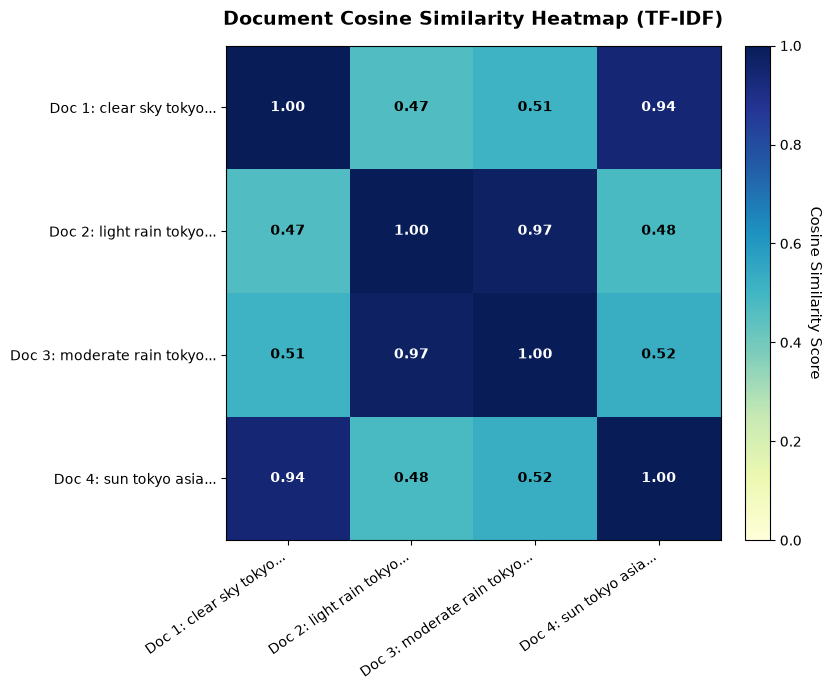

In [4]:
import matplotlib.pyplot as plt
import numpy as np

def visualize_data(cosine_matrix, texts_processed):
    """
    Visualize the cosine similarity matrix from the previous task. 

    Args:
        cosine_matrix (list): matrix of cosine similarity scores (values from 0.0 to 1.0 expected).
        texts_processed (list): list of texts, processed in previous task.

    Returns:
        None: None.
    """
    if cosine_matrix is None or len(cosine_matrix) == 0:
        print("No cosine similarity matrix to visualize.")
        return None

    matrix = np.array(cosine_matrix, dtype=float)
    n = len(texts_processed)

    labels = []
    for i, text in enumerate(texts_processed):
        first_words = " ".join(text.split()[:3])
        labels.append(f"Doc {i + 1}: {first_words}...")

    fig_size = max(7, n * 1.4)
    fig, ax = plt.subplots(figsize=(fig_size + 1.5, fig_size))
    im = ax.imshow(matrix, cmap="YlGnBu", vmin=0.0, vmax=1.0)

    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label("Cosine Similarity Score", rotation=270, labelpad=15, fontsize=11)

    ax.set_xticks(np.arange(n))
    ax.set_yticks(np.arange(n))
    ax.set_xticklabels(labels, rotation=35, ha="right", fontsize=10)
    ax.set_yticklabels(labels, fontsize=10)

    # Annotate similarity scores inside each heatmap cell
    for i in range(n):
        for j in range(n):
            score = matrix[i, j]
            text_color = "white" if score > 0.55 else "black"
            ax.text(
                j, i, f"{score:.2f}",
                ha="center", va="center",
                color=text_color, fontsize=10, fontweight="bold"
            )

    ax.set_title("Document Cosine Similarity Heatmap (TF-IDF)", fontsize=14, fontweight="bold", pad=15)
    plt.tight_layout()
    plt.show()
    return None

visualize_data(cosine_matrix, texts_processed)

## Analyse your own text using TFIDF (or any other method)

Analyse your own text using previous methods. You may use API fetching to get text data, download texts from Kaggle or use any texts you want. Find cosine similarities and visualize them

Recommendation: use sentence_transform / openai embedding model

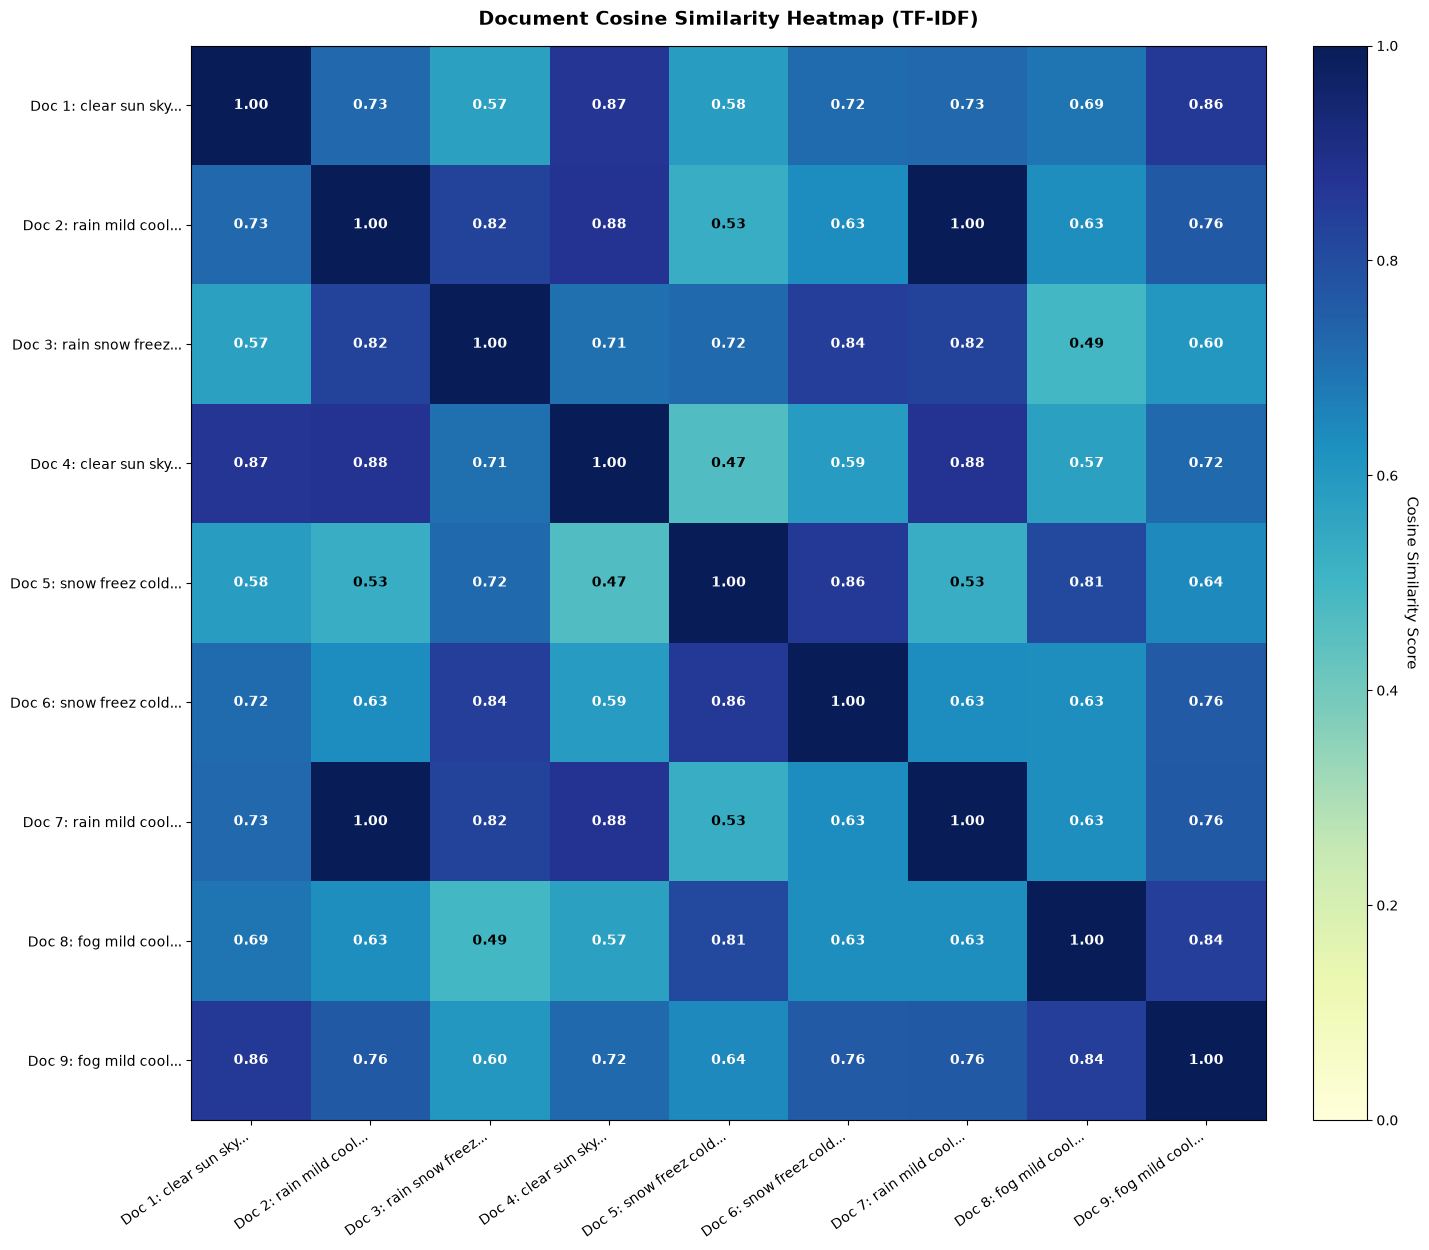

In [5]:
import csv
import os

def get_texts():
    """
    Get the texts you want to analyse. Either API fetching, Kaggle or any other source.
    Extracts diverse weather event reports from resources/weather.csv.

    Args:
        None: None.

    Returns:
        list: list of texts.
    """
    csv_path = os.path.join("resources", "weather.csv")
    if not os.path.exists(csv_path) and os.path.exists("weather.csv"):
        csv_path = "weather.csv"

    selected_texts = []
    target_events = ["Rain", "Rain", "Snow", "Snow", "Fog", "Fog", "Rain-Snow", "", ""]
    collected_counts = {}

    if os.path.exists(csv_path):
        with open(csv_path, mode="r", encoding="utf-8") as f:
            reader = csv.DictReader(f)
            for row in reader:
                clean_row = {k.strip(): (v.strip() if v else "") for k, v in row.items() if k}
                event = clean_row.get("Events", "")
                needed = target_events.count(event)
                if needed > 0 and collected_counts.get(event, 0) < needed:
                    collected_counts[event] = collected_counts.get(event, 0) + 1
                    date = clean_row.get("CET", "Unknown date")
                    max_t = float(clean_row.get("Max TemperatureC") or 0)
                    min_t = float(clean_row.get("Min TemperatureC") or 0)
                    hum = float(clean_row.get("Mean Humidity") or 0)
                    wind = float(clean_row.get("Max Wind SpeedKm/h") or 0)
                    vis = float(clean_row.get("Mean VisibilityKm") or 10)
                    cloud = clean_row.get("CloudCover", "0")

                    event_label = event.replace("-", " and ") if event else "Clear sunny sky"
                    temp_desc = "freezing cold winter" if max_t <= 5 else ("hot summer" if max_t >= 25 else "mild cool")
                    vis_desc = "low dense mist visibility" if vis <= 6 else "clear high visibility"
                    wind_desc = "strong stormy wind gusts" if wind >= 25 else "calm gentle wind breeze"

                    report = (
                        f"{event_label} on {date}: {temp_desc} max temp {max_t}C and min temp {min_t}C, "
                        f"avg hum {hum}%, {wind_desc} at max spd {wind}km/h, "
                        f"{vis_desc} {vis}km, cloud cover {cloud}."
                    )
                    selected_texts.append(report)
                if len(selected_texts) >= len(target_events):
                    break

    return selected_texts

texts = get_texts()
texts_processed = process_texts(texts)
cosine_matrix = calcuate_tfidf(texts_processed)
visualize_data(cosine_matrix, texts_processed)